<a href="https://colab.research.google.com/github/ntf0/Big-Data-Project/blob/main/Dataset1_Supervised_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ITCS458 Group Project: Dataset 1 (Supervised Learning)
## Higher Education Students Performance Evaluation

**Main question:** Can machine learning classify university students into LOW, MEDIUM and HIGH academic performance groups using the available student information?

**Algorithms:** Random Forest, XGBoost, CatBoost

**Notebook outline**
1. Setup and imports
2. Part 1: Load and explore the dataset
3. Target creation (LOW / MEDIUM / HIGH)
4. Preprocessing
5. Part 2: Apply three algorithms
6. Part 3: Evaluate the three models
7. Part 4: Compare the three algorithms
8. Conclusion

In [26]:
!pip install -q catboost

In [27]:



import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Model selection
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# Supervised learning algorithms
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
)

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
RANDOM_STATE = 42

## 2. Part 1: Load and Explore the Dataset

In [28]:
from google.colab import files
import io

uploaded = files.upload()          # choose "Academic Students Performance.csv"
file_name = list(uploaded.keys())[0]
print('Uploaded:', file_name)

df = pd.read_csv(io.BytesIO(uploaded[file_name]))
df.columns = df.columns.str.strip()   # remove accidental spaces in column names

print(f'Rows: {df.shape[0]}')
print(f'Columns: {df.shape[1]}')

Saving Academic Students Performance.csv to Academic Students Performance (1).csv
Uploaded: Academic Students Performance (1).csv
Rows: 145
Columns: 33


In [29]:
df.head()

,STUDENT ID,1,2,3,4,5,6,7,8,9,...,23,24,25,26,27,28,29,30,COURSE ID,GRADE
0,STUDENT1,2,2,3,3,1,2,2,1,1,...,1,1,3,2,1,2,1,1,1,1
1,STUDENT2,2,2,3,3,1,2,2,1,1,...,1,1,3,2,3,2,2,3,1,1
2,STUDENT3,2,2,2,3,2,2,2,2,4,...,1,1,2,2,1,1,2,2,1,1
3,STUDENT4,1,1,1,3,1,2,1,2,1,...,1,2,3,2,2,1,3,2,1,1
4,STUDENT5,2,2,1,3,2,2,1,3,1,...,2,1,2,2,2,1,2,2,1,1


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145 entries, 0 to 144
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   STUDENT ID  145 non-null    object
 1   1           145 non-null    int64 
 2   2           145 non-null    int64 
 3   3           145 non-null    int64 
 4   4           145 non-null    int64 
 5   5           145 non-null    int64 
 6   6           145 non-null    int64 
 7   7           145 non-null    int64 
 8   8           145 non-null    int64 
 9   9           145 non-null    int64 
 10  10          145 non-null    int64 
 11  11          145 non-null    int64 
 12  12          145 non-null    int64 
 13  13          145 non-null    int64 
 14  14          145 non-null    int64 
 15  15          145 non-null    int64 
 16  16          145 non-null    int64 
 17  17          145 non-null    int64 
 18  18          145 non-null    int64 
 19  19          145 non-null    int64 
 20  20        

In [31]:
df.describe()

,1,2,3,4,5,6,7,8,9,10,...,23,24,25,26,27,28,29,30,COURSE ID,GRADE
count,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000,...,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000
mean,1.620690,1.600000,1.944828,3.572414,1.662069,1.600000,1.579310,1.627586,1.620690,1.731034,...,1.337931,1.165517,2.544828,2.055172,2.393103,1.806897,3.124138,2.724138,4.131034,3.227586
std,0.613154,0.491596,0.537216,0.805750,0.474644,0.491596,0.495381,1.020245,1.061112,0.783999,...,0.614870,0.408483,0.564940,0.674736,0.604343,0.810492,1.301083,0.916536,3.260145,2.197678
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,1.000000,1.000000,2.000000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,2.000000,2.000000,2.000000,1.000000,2.000000,2.000000,1.000000,1.000000
50%,2.000000,2.000000,2.000000,3.000000,2.000000,2.000000,2.000000,1.000000,1.000000,2.000000,...,1.000000,1.000000,3.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,3.000000
75%,2.000000,2.000000,2.000000,4.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,...,2.000000,1.000000,3.000000,3.000000,3.000000,2.000000,4.000000,3.000000,7.000000,5.000000
max,3.000000,2.000000,3.000000,5.000000,2.000000,2.000000,2.000000,5.000000,4.000000,4.000000,...,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,5.000000,4.000000,9.000000,7.000000


### Missing values and duplicate rows

In [32]:
print('Missing values per column (total):', df.isnull().sum().sum())
print('Duplicate rows (all columns):', df.duplicated().sum())

# Duplicates ignoring the ID column (same answers, different student)
feature_cols_check = [c for c in df.columns if c != 'STUDENT ID']
print('Duplicate rows (ignoring STUDENT ID):', df.duplicated(subset=feature_cols_check).sum())

Missing values per column (total): 0
Duplicate rows (all columns): 0
Duplicate rows (ignoring STUDENT ID): 0


### Output column
The output (target) column is **GRADE** (original values 0 to 7). `STUDENT ID` is only an identifier, and `1` to `30` are survey answers.

Original grade distribution:
       Count  Share %
GRADE                
0          8      5.5
1         35     24.1
2         24     16.6
3         21     14.5
4         10      6.9
5         17     11.7
6         13      9.0
7         17     11.7


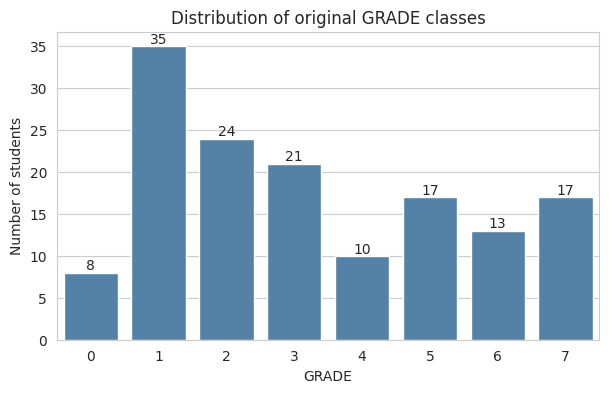

In [33]:
print('Original grade distribution:')
grade_counts = df['GRADE'].value_counts().sort_index()
print(pd.DataFrame({'Count': grade_counts, 'Share %': (grade_counts / len(df) * 100).round(1)}))

plt.figure(figsize=(7, 4))
ax = sns.countplot(x='GRADE', data=df, color='steelblue')
ax.bar_label(ax.containers[0])
plt.title('Distribution of original GRADE classes')
plt.xlabel('GRADE')
plt.ylabel('Number of students')
plt.show()

COURSE ID distribution:
COURSE ID
1    66
2     2
3     8
4     4
5     7
6     8
7    15
8    14
9    21
Name: count, dtype: int64


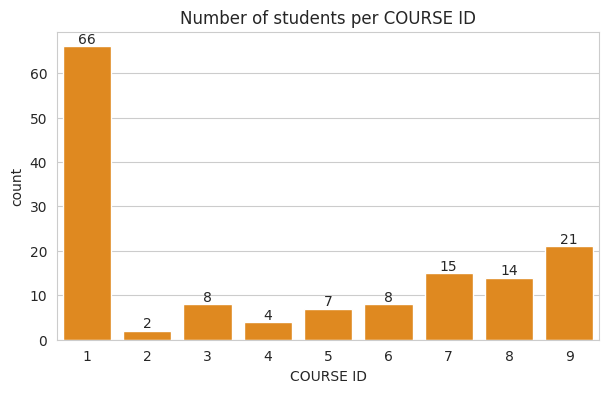

In [34]:
print('COURSE ID distribution:')
print(df['COURSE ID'].value_counts().sort_index())

plt.figure(figsize=(7, 4))
ax = sns.countplot(x='COURSE ID', data=df, color='darkorange')
ax.bar_label(ax.containers[0])
plt.title('Number of students per COURSE ID')
plt.show()

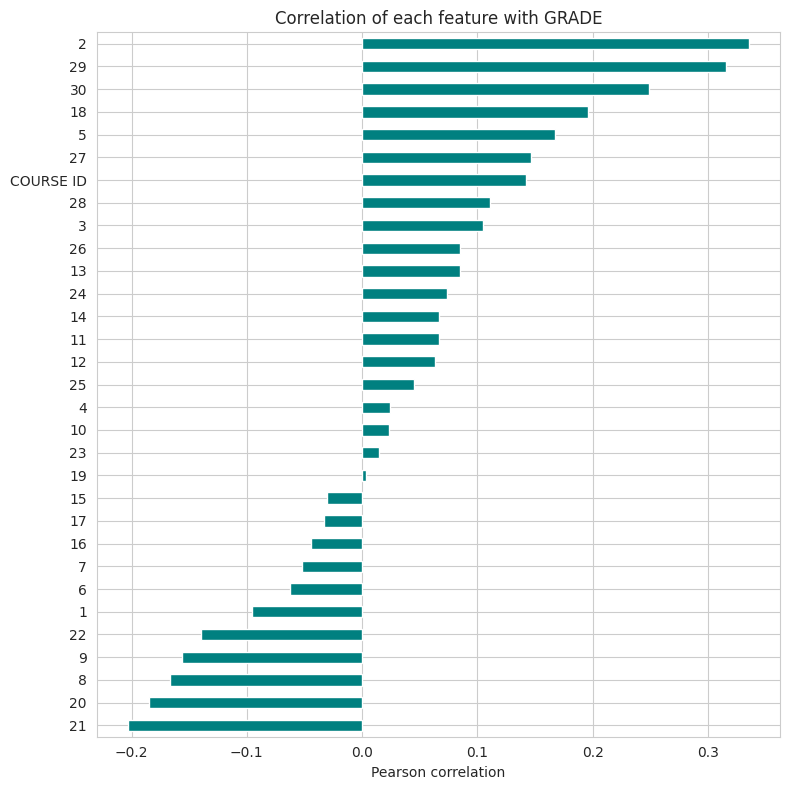

Top 5 positive correlations:
5     0.167
18    0.196
30    0.249
29    0.315
2     0.336
dtype: float64

Top 5 negative correlations:
21   -0.203
20   -0.185
8    -0.166
9    -0.156
22   -0.140
dtype: float64


In [35]:
# Correlation of each survey feature with the original GRADE
feature_cols = [c for c in df.columns if c not in ['STUDENT ID', 'GRADE']]
corr_with_grade = df[feature_cols].corrwith(df['GRADE']).sort_values()

plt.figure(figsize=(8, 8))
corr_with_grade.plot(kind='barh', color='teal')
plt.title('Correlation of each feature with GRADE')
plt.xlabel('Pearson correlation')
plt.tight_layout()
plt.show()

print('Top 5 positive correlations:')
print(corr_with_grade.tail(5).round(3))
print()
print('Top 5 negative correlations:')
print(corr_with_grade.head(5).round(3))

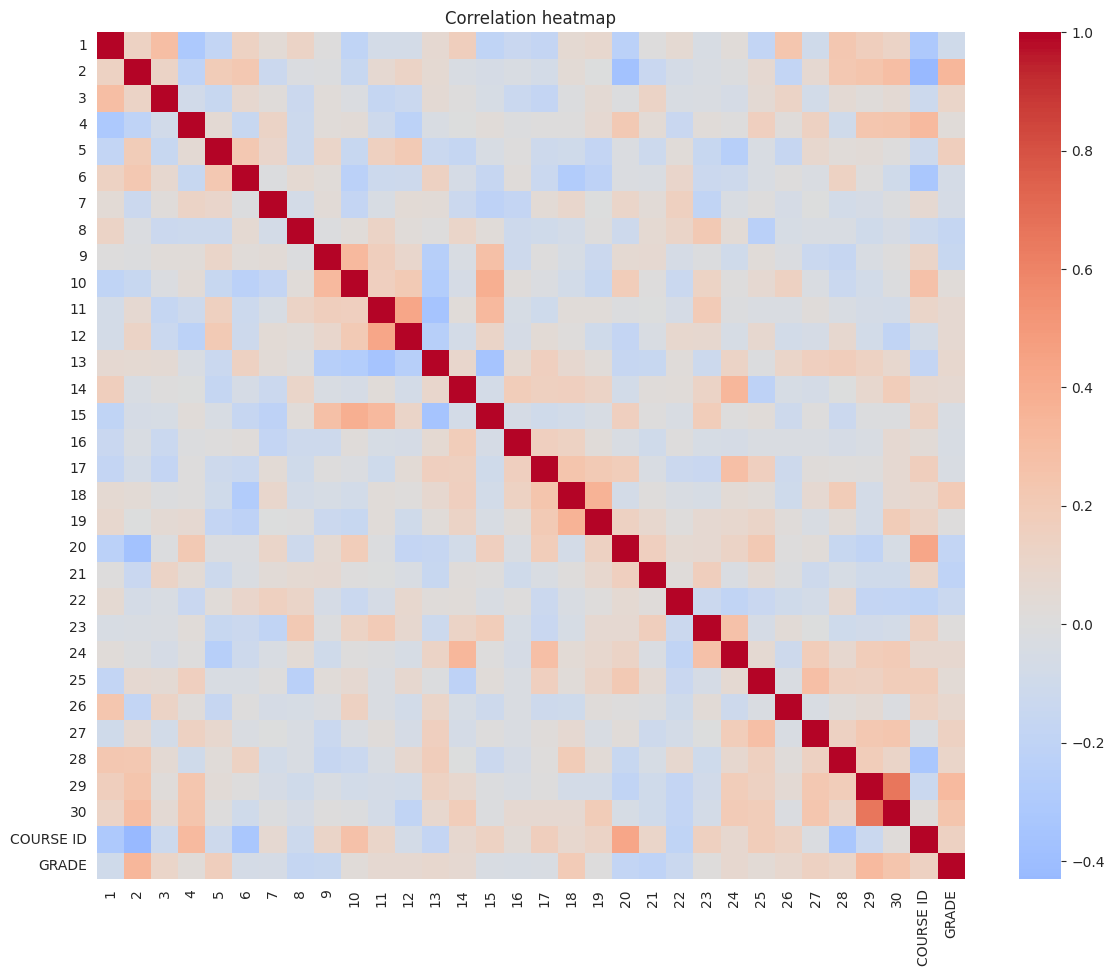

In [36]:
# Correlation heatmap of the numeric features
plt.figure(figsize=(14, 11))
sns.heatmap(df.drop(columns=['STUDENT ID']).corr(), cmap='coolwarm', center=0)
plt.title('Correlation heatmap')
plt.show()

## 3. Target Creation: LOW / MEDIUM / HIGH

The assignment asks for three performance groups built from the original grade.
Mapping used (balanced groups):

| Group | Original GRADE |
|---|---|
| LOW | 0, 1 |
| MEDIUM | 2, 3, 4 |
| HIGH | 5, 6, 7 |

Per the UCI documentation, grades 0 to 7 correspond to Fail, DD, DC, CC, CB, BB, BA, AA.

             Count  Share %
PERFORMANCE                
LOW             43     29.7
MEDIUM          55     37.9
HIGH            47     32.4


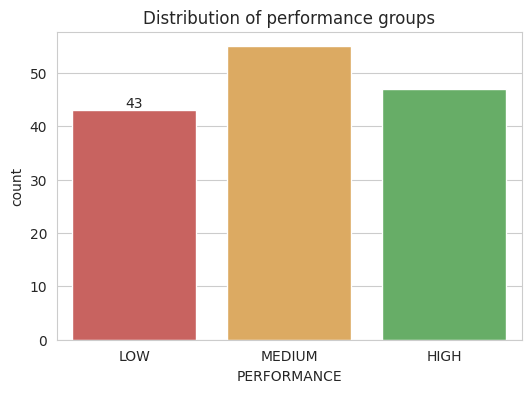

In [37]:
def grade_group(g):
    if g <= 1:
        return 'LOW'
    elif g <= 4:
        return 'MEDIUM'
    return 'HIGH'

df['PERFORMANCE'] = df['GRADE'].apply(grade_group)

order = ['LOW', 'MEDIUM', 'HIGH']
counts = df['PERFORMANCE'].value_counts().reindex(order)
print(pd.DataFrame({'Count': counts, 'Share %': (counts / len(df) * 100).round(1)}))

plt.figure(figsize=(6, 4))
ax = sns.countplot(x='PERFORMANCE', data=df, order=order, palette=['#d9534f', '#f0ad4e', '#5cb85c'])
ax.bar_label(ax.containers[0])
plt.title('Distribution of performance groups')
plt.show()

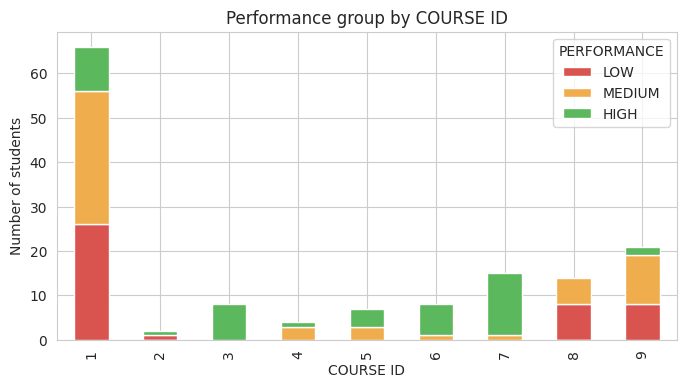

In [38]:
# Performance group by course
ct = pd.crosstab(df['COURSE ID'], df['PERFORMANCE'])[order]
ct.plot(kind='bar', stacked=True, figsize=(8, 4), color=['#d9534f', '#f0ad4e', '#5cb85c'])
plt.title('Performance group by COURSE ID')
plt.ylabel('Number of students')
plt.show()

## 4. Preprocessing

Decisions (same basis for all three algorithms):
- Drop `STUDENT ID` (identifier) and `GRADE` (it would leak the answer into the features).
- Treat `COURSE ID` as a category and one-hot encode it.
- Encode the target as LOW = 0, MEDIUM = 1, HIGH = 2 (XGBoost needs numeric labels).
- Stratified 80/20 train/test split so every class appears in both sets.
- No scaling: all three models are tree based and do not need it.

In [39]:
label_map = {'LOW': 0, 'MEDIUM': 1, 'HIGH': 2}
class_names = ['LOW', 'MEDIUM', 'HIGH']

y = df['PERFORMANCE'].map(label_map)
X = df.drop(columns=['STUDENT ID', 'GRADE', 'PERFORMANCE'])
X = pd.get_dummies(X, columns=['COURSE ID'], prefix='COURSE', dtype=int)

print('Feature matrix shape:', X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print('Train size:', X_train.shape[0], '| Test size:', X_test.shape[0])
print()
print('Train class counts:')
print(y_train.map({v: k for k, v in label_map.items()}).value_counts().reindex(order))
print('Test class counts:')
print(y_test.map({v: k for k, v in label_map.items()}).value_counts().reindex(order))

Feature matrix shape: (145, 39)
Train size: 116 | Test size: 29

Train class counts:
PERFORMANCE
LOW       34
MEDIUM    44
HIGH      38
Name: count, dtype: int64
Test class counts:
PERFORMANCE
LOW        9
MEDIUM    11
HIGH       9
Name: count, dtype: int64


## 5. Part 2: Apply Three Algorithms

All models use the same train/test split, the same features and the same random seed.

In [40]:
models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        objective='multi:softprob', eval_metric='mlogloss',
        random_state=RANDOM_STATE
    ),
    'CatBoost': CatBoostClassifier(
        iterations=300, learning_rate=0.05, depth=4,
        loss_function='MultiClass', random_seed=RANDOM_STATE, verbose=0
    ),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f'{name} trained.')

Random Forest trained.
XGBoost trained.
CatBoost trained.


## 6. Part 3: Evaluate the Three Models

In [41]:
results = []
predictions = {}
probabilities = {}

for name, model in models.items():
    y_pred = np.asarray(model.predict(X_test)).ravel().astype(int)
    y_proba = model.predict_proba(X_test)

    predictions[name] = y_pred
    probabilities[name] = y_proba

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (macro)': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'Recall (macro)': recall_score(y_test, y_pred, average='macro', zero_division=0),
        'F1 (macro)': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'ROC AUC (OvR)': roc_auc_score(y_test, y_proba, multi_class='ovr', average='macro'),
    })

results_df = pd.DataFrame(results).set_index('Model').round(4)
results_df

,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC AUC (OvR)
Model,,,,,
Random Forest,0.5862,0.6569,0.5758,0.5905,0.7939
XGBoost,0.6897,0.7038,0.6936,0.6972,0.8224
CatBoost,0.6207,0.6905,0.6128,0.6309,0.8160


In [42]:
# Detailed per-class report for each model
for name in models:
    print('=' * 60)
    print(name)
    print('=' * 60)
    print(classification_report(y_test, predictions[name], target_names=class_names, zero_division=0))

Random Forest
              precision    recall  f1-score   support

         LOW       0.50      0.33      0.40         9
      MEDIUM       0.47      0.73      0.57        11
        HIGH       1.00      0.67      0.80         9

    accuracy                           0.59        29
   macro avg       0.66      0.58      0.59        29
weighted avg       0.64      0.59      0.59        29

XGBoost
              precision    recall  f1-score   support

         LOW       0.60      0.67      0.63         9
      MEDIUM       0.64      0.64      0.64        11
        HIGH       0.88      0.78      0.82         9

    accuracy                           0.69        29
   macro avg       0.70      0.69      0.70        29
weighted avg       0.70      0.69      0.69        29

CatBoost
              precision    recall  f1-score   support

         LOW       0.57      0.44      0.50         9
      MEDIUM       0.50      0.73      0.59        11
        HIGH       1.00      0.67      0.80 

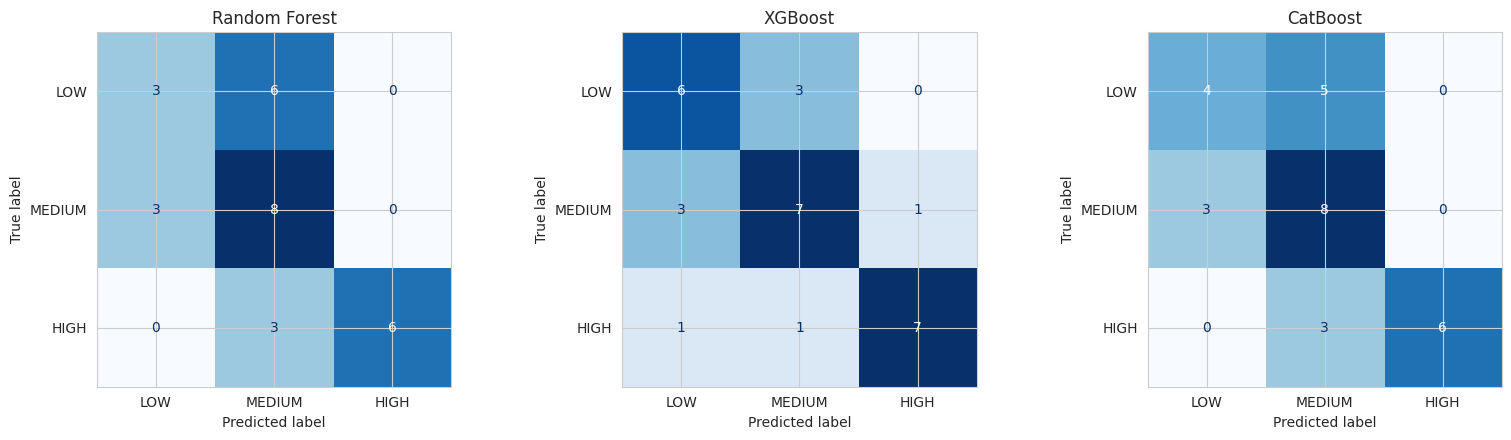

In [43]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, predictions[name], labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### Cross-validation (more reliable than one small test split)
With only 145 students, the test set has about 29 rows, so a single split can be noisy.
Stratified 5-fold cross-validation on the full dataset gives a steadier estimate.

In [44]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for name, model in models.items():
    acc = cross_val_score(model, X, y, cv=skf, scoring='accuracy')
    f1 = cross_val_score(model, X, y, cv=skf, scoring='f1_macro')
    cv_rows.append({
        'Model': name,
        'CV Accuracy (mean)': acc.mean(),
        'CV Accuracy (std)': acc.std(),
        'CV F1 macro (mean)': f1.mean(),
        'CV F1 macro (std)': f1.std(),
    })

cv_df = pd.DataFrame(cv_rows).set_index('Model').round(4)
cv_df

,CV Accuracy (mean),CV Accuracy (std),CV F1 macro (mean),CV F1 macro (std)
Model,,,,
Random Forest,0.5172,0.0872,0.5070,0.0842
XGBoost,0.4828,0.0488,0.4794,0.0492
CatBoost,0.5310,0.0468,0.5136,0.0523


## 7. Part 4: Compare the Three Algorithms

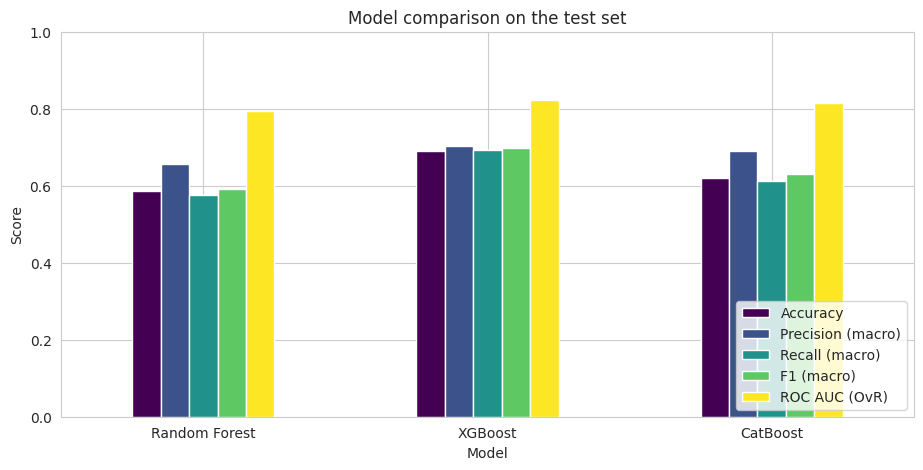

,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC AUC (OvR)
Model,,,,,
Random Forest,0.5862,0.6569,0.5758,0.5905,0.7939
XGBoost,0.6897,0.7038,0.6936,0.6972,0.8224
CatBoost,0.6207,0.6905,0.6128,0.6309,0.8160


In [45]:
# Side-by-side comparison chart
results_df.plot(kind='bar', figsize=(11, 5), colormap='viridis')
plt.title('Model comparison on the test set')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

results_df

In [46]:
# Best model by macro F1 (accuracy shown too)
best_by_f1 = results_df['F1 (macro)'].idxmax()
best_by_acc = results_df['Accuracy'].idxmax()
best_by_auc = results_df['ROC AUC (OvR)'].idxmax()

print('Best by F1 (macro):', best_by_f1)
print('Best by Accuracy  :', best_by_acc)
print('Best by ROC AUC   :', best_by_auc)

if len({best_by_f1, best_by_acc, best_by_auc}) == 1:
    print(f'\nAll three metrics agree: {best_by_f1} is the best model.')
else:
    print('\nThe metrics do NOT all agree. Discuss this in the report.')

Best by F1 (macro): XGBoost
Best by Accuracy  : XGBoost
Best by ROC AUC   : XGBoost

All three metrics agree: XGBoost is the best model.


In [47]:
# Which classes are confused most often? (largest off-diagonal cells)
for name in models:
    cm = confusion_matrix(y_test, predictions[name], labels=[0, 1, 2])
    errors = []
    for i in range(3):
        for j in range(3):
            if i != j and cm[i, j] > 0:
                errors.append((class_names[i], class_names[j], cm[i, j]))
    errors.sort(key=lambda t: t[2], reverse=True)
    print(name)
    if errors:
        for true_c, pred_c, n in errors[:3]:
            print(f'   true {true_c} predicted as {pred_c}: {n}')
    else:
        print('   no errors')
    print()

Random Forest
   true LOW predicted as MEDIUM: 6
   true MEDIUM predicted as LOW: 3
   true HIGH predicted as MEDIUM: 3

XGBoost
   true LOW predicted as MEDIUM: 3
   true MEDIUM predicted as LOW: 3
   true MEDIUM predicted as HIGH: 1

CatBoost
   true LOW predicted as MEDIUM: 5
   true MEDIUM predicted as LOW: 3
   true HIGH predicted as MEDIUM: 3



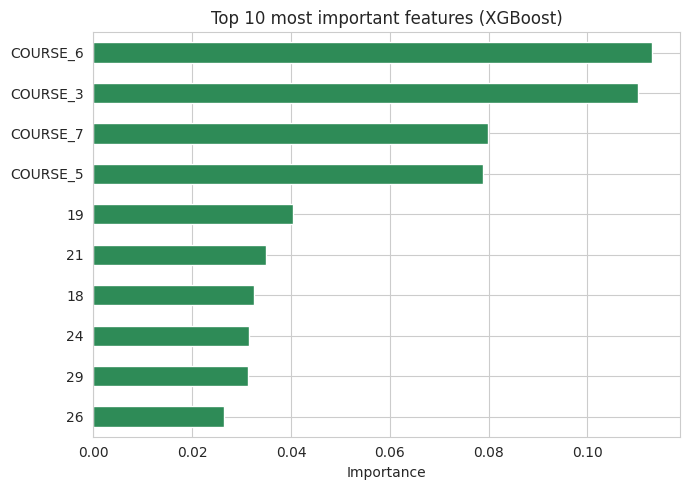

In [48]:
# Feature importance of the best model (by F1)
best_model = models[best_by_f1]

if best_by_f1 == 'CatBoost':
    importances = best_model.get_feature_importance()
else:
    importances = best_model.feature_importances_

imp = pd.Series(importances, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(7, 5))
imp[::-1].plot(kind='barh', color='seagreen')
plt.title(f'Top 10 most important features ({best_by_f1})')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

## 8. Conclusion (fill in after running)

**Best classifier:** _write the model name_ (Accuracy = __, F1 = __, ROC AUC = __).

**Do all metrics agree?** _yes / no, and why._

**Most confused classes:** _for example MEDIUM is often confused with LOW and HIGH, because it sits between the two._

**Why the best model is preferred:** _higher and more stable scores (compare with cross-validation), handles small data and ordinal features well, etc._

**Limitations:** only 145 students, so the test set is small and results can change with a different split; the LOW / MEDIUM / HIGH grouping is our own choice.